In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)

In [2]:
df = pd.read_csv('/mnt/user-data/uploads/train_2.csv')
print(df.shape)
df = df.drop(columns='id').sample(30000, random_state=42).reset_index(drop=True)
df['satisfaction'] = df['satisfaction'].astype(int)
print(df['satisfaction'].value_counts(normalize=True))
df.head()

(699635, 23)
satisfaction
0    0.555033
1    0.444967
Name: proportion, dtype: float64


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,42,2246,2,2,2,2,4,4,5,4,...,4,2,3,0,0.0,Female,Loyal Customer,Business travel,Business,1
1,17,1416,2,2,2,2,2,2,2,2,...,2,1,2,0,0.0,Male,disloyal Customer,Business travel,Eco,0
2,48,2201,1,1,1,1,3,4,4,4,...,4,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
3,46,3472,5,5,5,5,3,4,5,5,...,5,4,4,0,0.0,Male,Loyal Customer,Business travel,Business,1
4,35,577,4,5,4,3,1,4,4,1,...,5,4,1,0,0.0,Male,Loyal Customer,Personal Travel,Eco,1


In [3]:
X = df.drop(columns='satisfaction')
y = df['satisfaction']

In [4]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols)
])

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (24000, 21) | Test: (6000, 21)


In [6]:
model = Pipeline([
    ('prep', preprocess),
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spar

In [7]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [8]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print('Confusion Matrix:\n', cm)
print(f'TN={tn} FP={fp} FN={fn} TP={tp}')

Confusion Matrix:
 [[3080  250]
 [ 268 2402]]
TN=3080 FP=250 FN=268 TP=2402


In [9]:
results = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'Specificity': tn / (tn + fp),
    'F1-Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
}
for k, v in results.items():
    print(f'{k}: {v:.4f}')

Accuracy: 0.9137
Precision: 0.9057
Recall: 0.8996
Specificity: 0.9249
F1-Score: 0.9027
ROC-AUC: 0.9507


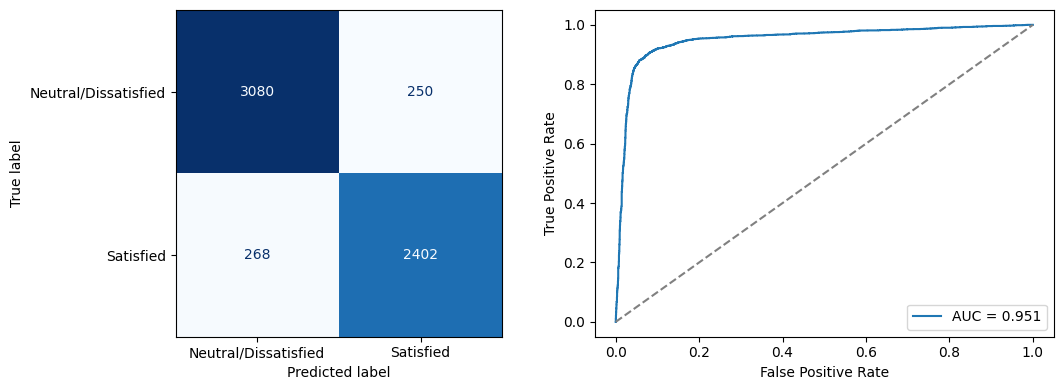

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=['Neutral/Dissatisfied', 'Satisfied']).plot(ax=ax[0], cmap='Blues', colorbar=False)
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {results['ROC-AUC']:.3f}")
ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].legend()
plt.tight_layout()
plt.show()

In [11]:
pos_rate = y.mean()
print(f'Positive class (satisfied) share: {pos_rate:.1%}')
print('Most appropriate metric: F1-Score, supported by ROC-AUC.')
print('Reason: the classes are fairly balanced, so accuracy is reliable here, but F1 summarizes precision and')
print('recall together (both error types matter for customer satisfaction), and ROC-AUC shows how well the')
print('model separates the classes across all thresholds, independent of the cutoff chosen.')

Positive class (satisfied) share: 44.5%
Most appropriate metric: F1-Score, supported by ROC-AUC.
Reason: the classes are fairly balanced, so accuracy is reliable here, but F1 summarizes precision and
recall together (both error types matter for customer satisfaction), and ROC-AUC shows how well the
model separates the classes across all thresholds, independent of the cutoff chosen.
